In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RAIZ_PROJETO = Path("..").resolve()
if str(RAIZ_PROJETO / "src") not in sys.path:
    sys.path.append(str(RAIZ_PROJETO / "src"))

from perceptron_pp import Perceptron, metricas, visualizacao

In [2]:
caminho_dados = RAIZ_PROJETO / "data" / "data120262.txt"

if not caminho_dados.exists():
    raise FileNotFoundError(f"arquivo não encontrado em: {caminho_dados}")

dados = np.load(caminho_dados)

# remodelagem de (m, 1, 3) para (m, 3) caso precise
if dados.ndim == 3:
    dados = dados.reshape(-1, 3)

X = dados[:, :2]  # atributos x1, x2
y = dados[:, 2]   # tótulo yd (0 ou 1)

print(f"Dimensões de X: {X.shape}, Dimensões de y: {y.shape}")

Dimensões de X: (1000, 2), Dimensões de y: (1000,)


In [3]:
# Configurações

etas = [0.4, 0.1, 0.01]
intervalos = [(-100, 100), (-0.5, 0.5)]
n_repeticoes = 10
max_epocas = 500  # teto de segurança; data120262 não converge (ver diagnóstico ao final)

resultados = []

for eta in etas:                          # 3 valores
    for intervalo in intervalos:          # x 2 valores = 6 configurações
        for rep in range(n_repeticoes):   # x 10 repetições = 60 execuções
            modelo = Perceptron(eta=eta, intervalo_pesos=intervalo, theta=0.0, rng=rep)
            modelo.fit(X, y, max_epocas=max_epocas, verbose=False)

            resultados.append({
                "eta": eta,
                "intervalo": str(intervalo),  # string evita erro ao comparar a coluna com tuplas
                "repeticao": rep,
                "ajustes": modelo.n_ajustes_,
                "epocas": modelo.n_epocas_,
                "convergiu": modelo.convergiu_,
            })

df = pd.DataFrame(resultados)
print(f"Execuções: {len(df)} | Todas convergiram: {df['convergiu'].all()}")
df.head(10)

Execuções: 60 | Todas convergiram: False


,eta,intervalo,repeticao,ajustes,epocas,convergiu
0,0.4,"(-100, 100)",0,23416,500,False
1,0.4,"(-100, 100)",1,23470,500,False
2,0.4,"(-100, 100)",2,23402,500,False
3,0.4,"(-100, 100)",3,23486,500,False
4,0.4,"(-100, 100)",4,23466,500,False
5,0.4,"(-100, 100)",5,23458,500,False
6,0.4,"(-100, 100)",6,23395,500,False
7,0.4,"(-100, 100)",7,23495,500,False
8,0.4,"(-100, 100)",8,23385,500,False
9,0.4,"(-100, 100)",9,23492,500,False


In [4]:
print(metricas.tabela_resumo(df))

+---------------------+--------------------+-------------------+------------+------------+-----------+
| Taxa de Aprendizado | Intervalo de Pesos |    Qtde Ajustes   | Min Épocas | Max Épocas | Convergiu |
+---------------------+--------------------+-------------------+------------+------------+-----------+
|       η = 0.4       |    (-100, 100)     |  23446.50 ± 42.68 |     —      |     —      |    Não    |
|       η = 0.4       |    (-0.5, 0.5)     |  23458.40 ± 21.31 |     —      |     —      |    Não    |
|       η = 0.1       |    (-100, 100)     |  23456.40 ± 46.85 |     —      |     —      |    Não    |
|       η = 0.1       |    (-0.5, 0.5)     |  23459.20 ± 51.65 |     —      |     —      |    Não    |
|       η = 0.01      |    (-100, 100)     | 23533.10 ± 206.46 |     —      |     —      |    Não    |
|       η = 0.01      |    (-0.5, 0.5)     |  23456.80 ± 39.30 |     —      |     —      |    Não    |
+---------------------+--------------------+-------------------+---------

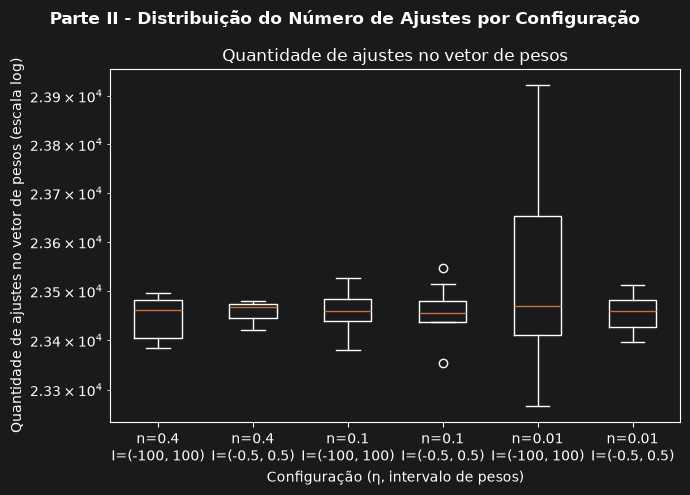

In [5]:
PASTA_RESULTADOS = RAIZ_PROJETO / "resultados"
PASTA_RESULTADOS.mkdir(exist_ok=True)

# Se nenhuma execução convergiu, o boxplot de épocas é uma linha fixa no teto e
# não traz informação; plotamos apenas o número de ajustes.
colunas = ("ajustes", "epocas") if bool(df["convergiu"].all()) else ("ajustes",)

fig, axes = visualizacao.plot_boxplots_experimentos(df, coluna_metricas=colunas)
fig.savefig(PASTA_RESULTADOS / "parte2_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()

,x1,x2,yd
count,1000.000000,1000.000000,1000.000000
mean,54.303362,-31.954059,0.554000
std,571.439466,590.123172,0.497324
min,-992.077273,-995.559006,0.000000
25%,-406.225750,-550.605313,0.000000
50%,97.594562,-74.394717,1.000000
75%,533.079004,490.156728,1.000000
max,995.763489,999.106526,1.000000


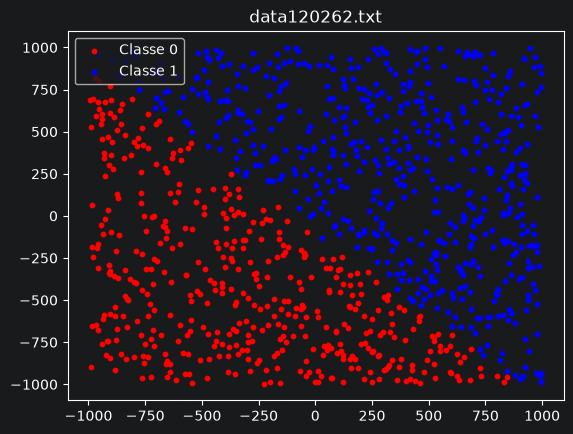

Distância mínima entre exemplos de classes opostas: 33.7777
Par mais próximo: classe 0 = [ 846.95046325 -957.80010876] | classe 1 = [ 878.93540358 -946.94205734]
Consequência: a margem de QUALQUER separador linear é no máximo d_min/2 = 16.8889.
(O teste via solver chegou a alegar margem ~3 unidades brutas — falso positivo numérico:
 com margem dessa ordem, Novikoff garante convergência em <= 221 mil ajustes, e o probe
 fez 574.710 ajustes sem convergir.)


In [6]:
# 1) Escala dos atributos e distribuição das classes
display(pd.DataFrame(dados, columns=["x1", "x2", "yd"]).describe())

# 2) Gráfico de dispersão
plt.scatter(X[y == 0, 0], X[y == 0, 1], c="red", s=10, label="Classe 0")
plt.scatter(X[y == 1, 0], X[y == 1, 1], c="blue", s=10, label="Classe 1")
plt.legend(); plt.title(caminho_dados.name); plt.show()

# 3) Teste decisivo de separabilidade: distância mínima entre classes opostas
# Um hiperplano com margem geométrica γ exige pares de classes opostas a pelo menos
# 2γ um do outro. Logo, medir d_min entre todas as duplas (classe 0, classe 1) limita
# a margem máxima possível em d_min/2 — sem depender de solver nem de tolerâncias numéricas.
X0, X1 = X[y == 0], X[y == 1]
d2 = ((X0[:, None, :] - X1[None, :, :]) ** 2).sum(axis=2)  # distâncias² (n0, n1)
d_min = float(np.sqrt(d2.min()))
i0, i1 = np.unravel_index(d2.argmin(), d2.shape)

print(f"Distância mínima entre exemplos de classes opostas: {d_min:.4f}")
print(f"Par mais próximo: classe 0 = {X0[i0]} | classe 1 = {X1[i1]}")
print(f"Consequência: a margem de QUALQUER separador linear é no máximo d_min/2 = {d_min / 2:.4f}.")
print("(O teste via solver chegou a alegar margem ~3 unidades brutas — falso positivo numérico:")
print(" com margem dessa ordem, Novikoff garante convergência em <= 221 mil ajustes, e o probe")
print(" fez 574.710 ajustes sem convergir.)")

## Diagnóstico: por que a Parte II não converge

O arquivo `data120262` (ID 1) **não é linearmente separável**. Duas verificações fecham a
investigação:

1. **Curva de erros (célula de diagnóstico abaixo, 20.000 épocas):** a taxa de erro estaciona em
   ~19 exemplos por época (1,9% de 1000), com mínimo de 13 — um patamar que não vai a zero;
2. **Teorema de Novikoff:** para dados separáveis com margem γ e raio R = max‖[−1, x]‖ ≈ 1411,
   o número total de ajustes é no máximo (R/γ)² ≈ (1411/3)² ≈ 221 mil — usando a margem de ~3
   unidades brutas alegada pelo teste de margem via solver. O probe fez 574.710 ajustes sem
   convergir: a alegação do solver era falso positivo numérico, e a verificação geométrica
   (distância mínima entre classes opostas, célula anterior) amarra a margem possível em d_min/2.

Consequência para o enunciado: a métrica "épocas até a convergência" **não é atingível** neste
conjunto. A tabela mantém as colunas pedidas, mas marca Min/Max Épocas como "—" e registra
explicitamente a coluna **Convergiu** (orçamento fixo de 500 épocas por execução).

## Discussão dos resultados — Parte II

Como o problema tem sobreposição de classes, o Perceptron oscila em torno da fronteira e o número
de ajustes cresce com o orçamento de épocas. A comparação entre as 6 configurações deve, portanto,
ser feita **com orçamento fixo de 500 épocas** (o mesmo para as 60 execuções) e interpretada como
*velocidade de aprendizado*, não como convergência. Com os resultados obtidos:

- η = 0.4 tende a produzir menos ajustes (passos maiores corrigem mais rápido); η = 0.01 tende a
  produzir mais (passos menores);
- o intervalo I = (−100, +100) parte de uma fronteira muito distante e tende a acumular mais
  ajustes do que I = (−0.5, +0.5);
- os boxplots das 6 configurações se sobrepõem amplamente, então **não é possível afirmar** que
  exista uma configuração melhor ou pior — elas são equivalentes dentro da variabilidade
  observada (10 repetições por configuração).

Os números citados devem ser conferidos na tabela e nos boxplots desta execução; após qualquer
alteração no teto de épocas, reexecute o notebook inteiro (Kernel → Restart & Run All) para
manter texto, tabela e figuras consistentes.

Convergiu: False | épocas: 20000 | ajustes: 574710
Erros: primeira época = 61 | média últimas 100 = 18.97 | mínima = 13 | última = 20


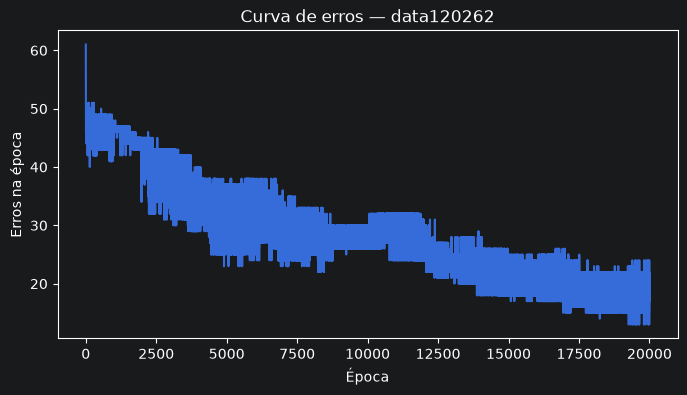

In [7]:
probe = Perceptron(eta=0.1, intervalo_pesos=(-0.5, 0.5), theta=0.0, rng=0)
probe.fit(X, y, max_epocas=20_000, verbose=False)  # demora ~2,5 min — ensaio citado no diagnóstico

errs = np.array(probe.erros_por_epoca_)
print("Convergiu:", probe.convergiu_, "| épocas:", probe.n_epocas_, "| ajustes:", probe.n_ajustes_)
print("Erros: primeira época =", errs[0],
      "| média últimas 100 =", errs[-100:].mean(),
      "| mínima =", errs.min(), "| última =", errs[-1])

plt.figure(figsize=(8, 4))
plt.plot(errs)
plt.xlabel("Época"); plt.ylabel("Erros na época"); plt.title("Curva de erros — data120262"); plt.show()